# **Decision Tree Regression on the Concrete Dataset**
Target: `strength` (concrete compressive strength, MPa)

**Decision Tree:** splits the data again and again with yes/no questions (e.g. "age > 0.5?") until it reaches a leaf. The prediction is the average strength of the samples in that leaf.

A tree with no limit memorizes the training data (overfit). So we tune these limits with `GridSearchCV` (5-fold, stratified):
- `max_depth` : how deep the tree can grow
- `min_samples_split` : minimum samples needed to split a node
- `min_samples_leaf` : minimum samples allowed in a leaf
- `ccp_alpha` : pruning strength (bigger = simpler tree)

> Trees do not need feature scaling, so there is no `StandardScaler` here.

### Import

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Dataset and Stratified Split
High-strength samples are rare, so we split on strength ranges to keep the same ratio in train and test.

In [4]:
df = pd.read_csv('../1. Data_Preprocessing/For_Regression/concrete_after_preprocessing.csv')
x = df.drop('strength', axis=1)
y = df['strength']

#Strength ranges (used only for stratification)
bins = pd.cut(y, bins=[0, 20, 35, 50, 65, 100], labels=False)

x_train, x_test, y_train, y_test, bins_train, _ = train_test_split(
    x, y, bins, test_size=0.2, random_state=42, stratify=bins)
print(x_train.shape, x_test.shape)

#Stratified 5-fold CV
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(x_train, bins_train))

(804, 8) (201, 8)


### Hyperparameter Grid

In [5]:
tree = DecisionTreeRegressor(random_state=42)

param_grid = {
    'max_depth': [3, 5, 7, 9, 12, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'ccp_alpha': [0, 0.01, 0.1, 0.5],
}

### GridSearchCV

In [6]:
%%time
grid = GridSearchCV(tree, param_grid, cv=cv, scoring='r2', n_jobs=-1, return_train_score=True)
grid.fit(x_train, y_train)

print('Best Params      :', grid.best_params_)
print('Best CV R2 score :', round(grid.best_score_, 4))
print('Train R2 score   :', round(grid.cv_results_['mean_train_score'][grid.best_index_], 4))

Best Params      : {'ccp_alpha': 0, 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV R2 score : 0.8346
Train R2 score   : 0.9974
CPU times: total: 35.6 s
Wall time: 59.9 s


### Test Set Evaluation

In [7]:
best_tree = grid.best_estimator_
y_pred = best_tree.predict(x_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print('MAE  :', round(mae, 4))
print('MSE  :', round(mse, 4))
print('RMSE :', round(rmse, 4))
print('R2   :', round(r2, 4))
print('Tree depth:', best_tree.get_depth(), '| Leaves:', best_tree.get_n_leaves())

MAE  : 5.056
MSE  : 72.113
RMSE : 8.4919
R2   : 0.7308
Tree depth: 21 | Leaves: 790


### Why tuning matters: unlimited tree vs tuned tree
An unlimited tree gets a perfect score on training data but does worse on new data (overfitting).

In [8]:
full_tree = DecisionTreeRegressor(random_state=42).fit(x_train, y_train)

compare = pd.DataFrame({
    'Unlimited Tree': [full_tree.score(x_train, y_train), full_tree.score(x_test, y_test), full_tree.get_depth()],
    'Tuned Tree':     [best_tree.score(x_train, y_train), best_tree.score(x_test, y_test), best_tree.get_depth()],
}, index=['Train R2', 'Test R2', 'Depth'])
compare.round(4)

,Unlimited Tree,Tuned Tree
Train R2,0.9974,0.9974
Test R2,0.7308,0.7308
Depth,21.0000,21.0000


### Visualization

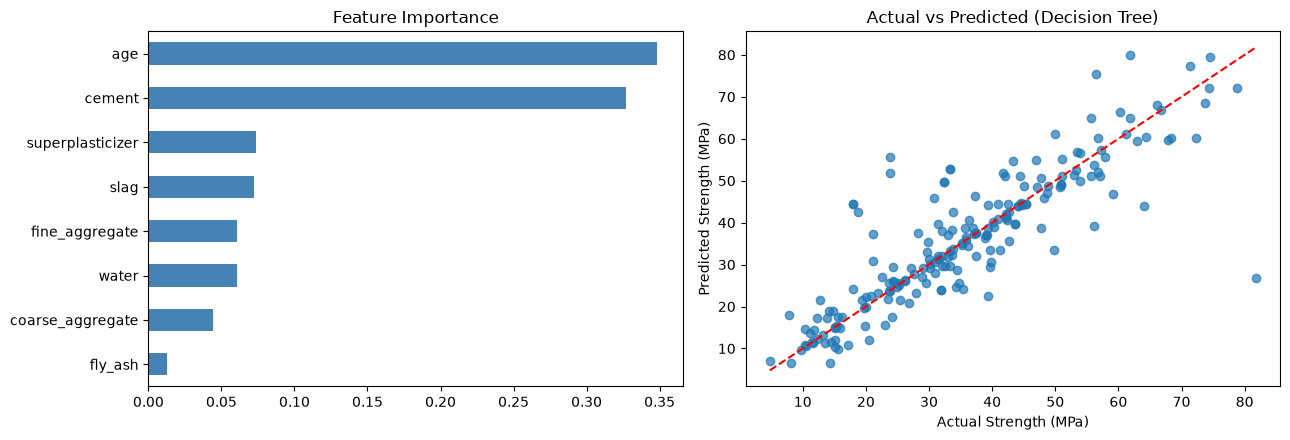

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

#Feature importance (which feature the tree uses most)
imp = pd.Series(best_tree.feature_importances_, index=x.columns).sort_values()
imp.plot(kind='barh', color='steelblue', ax=ax[0])
ax[0].set_title('Feature Importance')

#Actual vs Predicted
ax[1].scatter(y_test, y_pred, alpha=0.7)
ax[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
ax[1].set_xlabel('Actual Strength (MPa)'); ax[1].set_ylabel('Predicted Strength (MPa)')
ax[1].set_title('Actual vs Predicted (Decision Tree)')

plt.tight_layout(); plt.show()

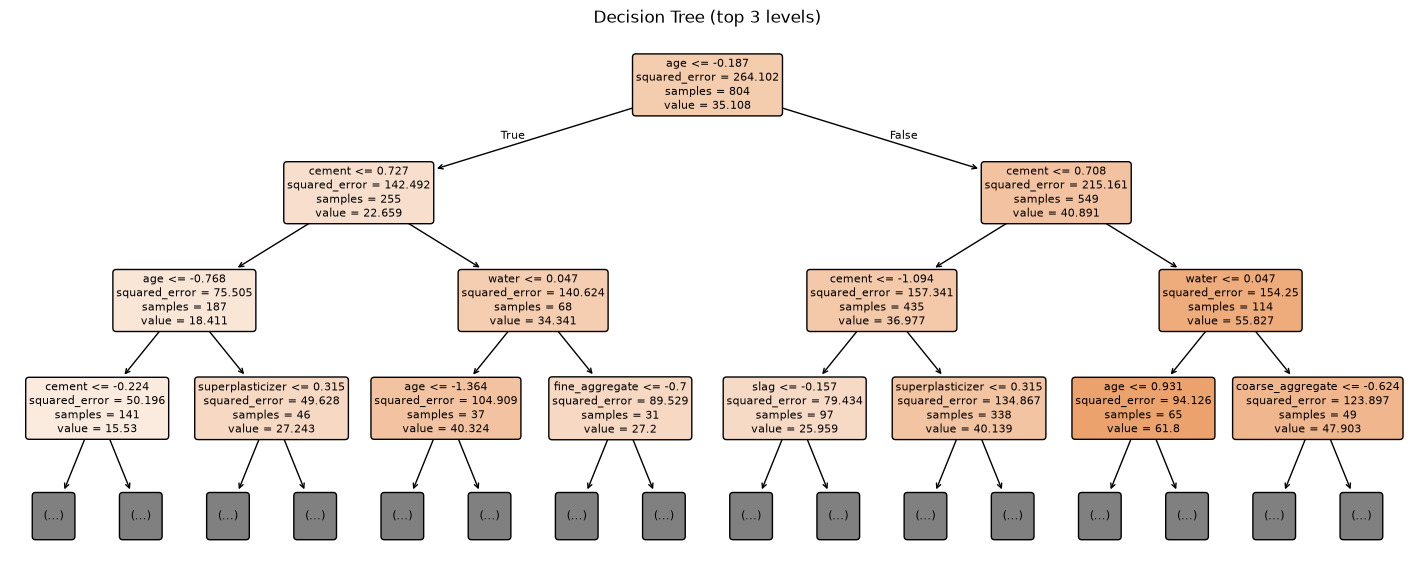

In [10]:
#Top of the tree (first 3 levels only, so it stays readable)
plt.figure(figsize=(18, 7))
plot_tree(best_tree, max_depth=3, feature_names=x.columns, filled=True, rounded=True, fontsize=8)
plt.title('Decision Tree (top 3 levels)')
plt.show()

### Save the Model (.pkl)
Best tree is trained once more on all data, then saved with `joblib`.

In [11]:
from sklearn.base import clone

final_tree = clone(best_tree)
final_tree.fit(x, y)

joblib.dump(final_tree, 'tree_concrete_model.pkl')
print('Saved: tree_concrete_model.pkl')

Saved: tree_concrete_model.pkl


### Load and Predict
These 5 rows were also used to train the final model, so predictions look better than reality. This cell only checks that the saved file loads and works. The honest accuracy is the **Test Set Evaluation** above (trained without the test rows).

In [12]:
model = joblib.load('tree_concrete_model.pkl')

new_rows = x_test.iloc[:5]
print('Predicted strength:', model.predict(new_rows).round(2))
print('Actual strength   :', y_test.iloc[:5].round(2).values)

Predicted strength: [21.97 15.07 18.03 30.23 68.3 ]
Actual strength   : [21.97 15.07 18.03 30.23 68.3 ]


### Download (Google Colab only)

In [13]:
try:
    from google.colab import files
    files.download('tree_concrete_model.pkl')
except ImportError:
    print('Not Colab - file is saved in the notebook folder.')

Not Colab - file is saved in the notebook folder.
